# ÖDEV 3 EK

2) Aşağıdaki dizi $A \cos \left(\omega_{0} n+\phi\right)$ formatında olan sinüzoidal işaretin tam bir periyot $n=$ $0,1, \ldots$ 7'ye kadar aldığı değerlere karşılık gelmektedir.

$$
[0,0.707106,-1,0.707106,0,-0.707106,1,-0.707106]
$$

Bu dizinin DFT'sinin genlik ve faz grafiklerine bakarak $A, \omega_{0}$ ve $\phi$ değerlerini bulunuz.

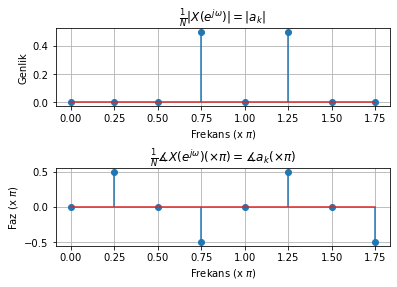

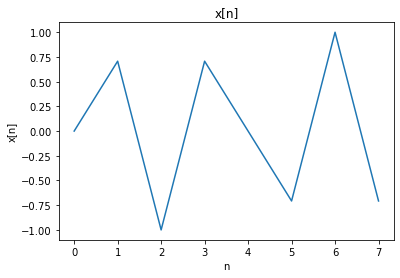

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fftpack import fft , ifft
N = 8
n = np.arange(0, N)
x = np.array([0, 0.707106, -1, 0.707106, 0, -0.707106, 1, -0.707106])
w_discrete=n*2*np.pi/len(n)
X = fft(x,N)
X_mag = np.abs(X/N)
X_ang = np.angle(X/N)

plt.figure()
plt.subplot(2,1,1)
plt.stem(w_discrete/np.pi, X_mag)
plt.title('$\\frac{1}{N}|X(e^{j\omega})|=|a_{k}|$')
plt.xlabel('Frekans (x $\pi$)' )
plt.ylabel('Genlik')
plt.grid()
plt.subplots_adjust(hspace=0.8, wspace=0.8)

plt.subplot(2,1,2)
plt.stem(w_discrete/np.pi , X_ang/np.pi)
plt.title('$\\frac{1}{N}\measuredangle X(e^{j\omega})(\\times \pi)=\measuredangle a_k(\\times \pi)$')
plt.xlabel('Frekans (x $\pi$)')
plt.ylabel('Faz (x $\pi$)')
plt.grid()

plt.figure()
plt.plot(n, x)
plt.title('x[n]')
plt.xlabel('n')
plt.ylabel('x[n]')
plt.show()




$$
 x[n] = \sum_{k=0}^{N-1} a_k e^{(j\frac{2\pi}{N}kn)} 
 = 0.5e^{\frac{-j\pi}{2}}e^{(j\frac{2\pi}{8}3n)} +0.5e^{\frac{j\pi}{2}}e^{(j\frac{2\pi}{8}5n)} 
 = 0.5e^{\frac{-j\pi}{2}}e^{(j\frac{3\pi}{4}n)} +0.5e^{\frac{j\pi}{2}}e^{(j\frac{5\pi}{4}n)} \\
 ve  $$
$$ e^{(j\frac{5\pi}{4}n)} = e^{(j(2\pi- \frac{3}{4}\pi )n)} \text{olduğundan} \\
 x[n] = 0.5e^{(j(\frac{3\pi}{4}n - \frac{\pi}{2}))} + 0.5e^{(-j(\frac{3\pi}{4}n - \frac{\pi}{2}))}  \\
 = cos(0.75n -\frac{\pi}{2})
$$


${ w_0 = 0.75\pi}$ <br>
${ \phi = -\frac{\pi}{2}}$ <br>
${ A = 1}$ <br>
${ A cos(w_0 n + \phi ) = cos(0.75n + \pi)}$



[ 6.12323400e-17  7.07106781e-01 -1.00000000e+00  7.07106781e-01
  3.06161700e-16 -7.07106781e-01  1.00000000e+00 -7.07106781e-01]


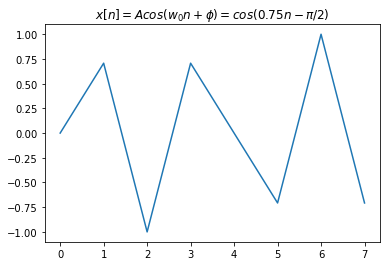

In [37]:
#{ A cos(w_0 n + \phi ) = cos(0.25n + \pi)}
A = 1
w_0 = 0.75 * np.pi
phi = -np.pi/2 #-0.5*np.pi
n = np.arange(0, 8)
x = A*np.cos(w_0*n + phi)
print(x)
plt.figure()
plt.plot(n, x)
plt.title('${ x[n] =  A cos(w_0 n + \phi ) = cos(0.75n - \pi /2)}$')
plt.show()


3) $x[n]=\cos \left(\frac{\pi}{3} n\right)$ işareti dürtü cevabı $h[n]=\delta[n]-\delta[n-1]$ olan bir sisteme giriş olarak verildiğinde sistemin çıkışında elde edilen $y[n]$ işaretini $n=0,1,2, \ldots, 10$ aralığında çizdiriniz. Not: $\mathrm{Bu}$ soruda, giriş işaretinin özfonksiyon olduğuna ve çıkış işaretinin $y[n]=$ $\left|H\left(e^{j \frac{\pi}{3}}\right)\right| \cos \left(\frac{\pi}{3} n+\angle H\left(e^{j \frac{\pi}{3}}\right)\right)$ ile bulunabileceğine dikkat ediniz. Dolayısıyla, birinci sorudan yararlanarak önce $\left|H\left(e^{j \frac{\pi}{3}}\right)\right|$ ve $\angle H\left(e^{j \frac{\pi}{3}}\right)$ değerlerini hesaplayınız ve bu değerleri print() komutu ile yazdırını ve yorum olarak bu değerleri belirtiniz.

H_abs: [1.]
H_phase: [1.04719755]


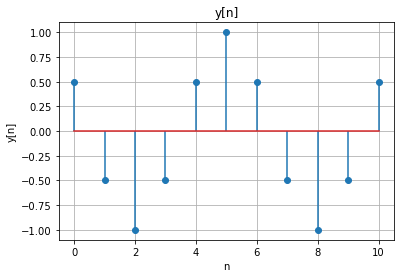

In [38]:
"""3) $x[n]=\cos \left(\frac{\pi}{3} n\right)$ işareti dürtü cevabı $h[n]=\delta[n]-\delta[n-1]$ olan bir sisteme giriş olarak verildiğinde sistemin çıkışında elde edilen $y[n]$ işaretini $n=0,1,2, \ldots, 10$ aralığında çizdiriniz. Not: $\mathrm{Bu}$ soruda, giriş işaretinin özfonksiyon olduğuna ve çıkış işaretinin $y[n]=$ $\left|H\left(e^{j \frac{\pi}{3}}\right)\right| \cos \left(\frac{\pi}{3} n+\angle H\left(e^{j \frac{\pi}{3}}\right)\right)$ ile bulunabileceğine dikkat ediniz. Dolayısıyla, birinci sorudan yararlanarak önce $\left|H\left(e^{j \frac{\pi}{3}}\right)\right|$ ve $\angle H\left(e^{j \frac{\pi}{3}}\right)$ değerlerini hesaplayınız ve bu değerleri print() komutu ile yazdırını ve yorum olarak bu değerleri belirtiniz."""
w_cont= np.array([np.pi/3])
H_abs=np.abs(2*np.sin(w_cont/2))
# X_phase -2pi ve 2 pi arasında olmalıdır
H_phase = np.array([-w/2+np.pi/2 if w>=0 else 0 for w in w_cont])
print('H_abs:', H_abs)
print('H_phase:', H_phase)

n = np.arange(0, 11)
yn = H_abs*np.cos(w_cont*n + H_phase)
plt.figure()
plt.stem(n, yn)
plt.title('y[n]')
plt.xlabel('n')
plt.ylabel('y[n]')
plt.grid()
plt.show()



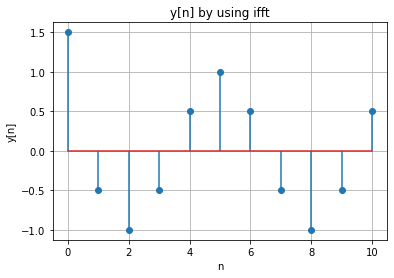

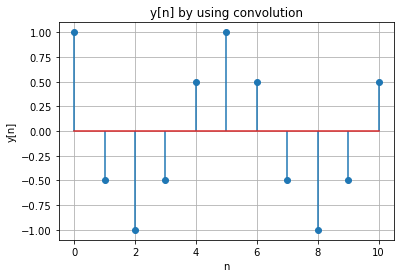

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fftpack import fft , ifft
N=11
n=np.arange(0,N)
#$h[n]=\delta[n]-\delta[n-1]$
def dirac(n):
    return np.where(n==0,1,0)

h_n=dirac(n)-dirac(n-1)
H_k=fft(h_n,N)
H_k_abs=np.abs(H_k)
H_k_phase=np.angle(H_k)
w_discrete=np.arange(0,N)*(2*np.pi/N)
#obtain y[n] using the frequency response when x[n]=cos((pi/3)n)
xn = np.cos((np.pi/3)*n)
X_k = fft(xn,N)
Y_k = X_k * H_k
y_n = ifft(Y_k)
plt.figure()
#plot yn
plt.stem(n,np.real(y_n))
plt.title('y[n] by using ifft')
plt.xlabel('n')
plt.ylabel('y[n]')
plt.grid()
plt.show()

#get yn by using convolution
y_n_conv = np.convolve(xn,h_n)[0:len(n)]
plt.figure()
#plot y[n] by using convolution
plt.stem(n,y_n_conv)
plt.title('y[n] by using convolution')
plt.xlabel('n')
plt.ylabel('y[n]')
plt.grid()


